## Manufacturing Statistical Analysis

### Connect to database and read SQL table

In [2]:
import pandas as pd
import pyodbc

In [3]:
conn_str = (
    "Driver={ODBC Driver 17 for SQL Server};"
    "Server=localhost\\SQLEXPRESS;"
    "Database=IRLManufacturingDB;" 
    "Trusted_Connection=yes;"
)
conn = pyodbc.connect(conn_str)
query = 'SELECT * FROM gold.machine1'

df = pd.read_sql(query, conn)

C:\Users\emartine\AppData\Local\Temp\ipykernel_14416\3036272784.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


### Data Exploration

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df.info()

Observations:
1. There are no NULL values.
2. Production_shift is a category but stands as an object datatype

In [25]:
df.head(5)

,production_datetime,production_shift,production_good_pieces,production_bad_pieces,production_target_pieces,machine_running_time,machine_planned_downtime,machine_idle_time,machine_breakdown_time,machine_availability_percent,production_performance_percent,production_quality_percent,overall_equipement_effectiveness_percent,production_year,production_month,total_production_pieces,total_no_scheduled_downtime
0,2024-01-01 06:00:00,Day,0,0,0.0,0.0,3600.0,0.0,0.0,0.0,0.0,0.0,0.0,2024,1,0,0.0
1,2024-01-01 07:00:00,Day,0,0,0.0,0.0,3600.0,0.0,0.0,0.0,0.0,0.0,0.0,2024,1,0,0.0
2,2024-01-01 08:00:00,Day,0,0,0.0,0.0,3600.0,0.0,0.0,0.0,0.0,0.0,0.0,2024,1,0,0.0
3,2024-01-01 09:00:00,Day,0,0,0.0,0.0,3600.0,0.0,0.0,0.0,0.0,0.0,0.0,2024,1,0,0.0
4,2024-01-01 10:00:00,Day,0,0,0.0,0.0,3600.0,0.0,0.0,0.0,0.0,0.0,0.0,2024,1,0,0.0


Observations:

3. **The data granularity is hourly (total machine time = 3600s)**
4. There are rows with no total production (good + bad pieces)
5. There are rows with the whole hour planned as downtime (machine_scheduled_downtime = 3600s)

Actions:

1. Delete duplicated columns (*production_datetime*)
2. Create dimension or change data-types as necessary
3. In the cases where there are not produced pieces, and where the whole hour is scheduled as downtime
is clear that we don't need this info since in the first case we can't use this info to analize production related metrics, and in the second case the whole time was planned as downtime, so there's not valuable information there.

In [ ]:
# 1.

# There are not duplicated columns.

In [ ]:
# 2.

df['production_shift'] = df['production_shift'].astype('category')
df['production_year'] = df['production_datetime'].dt.year
df['production_month'] = df['production_datetime'].dt.month

df['total_production_pieces'] = df['production_good_pieces'] + df['production_bad_pieces']
df['total_no_scheduled_downtime'] = df['machine_running_time'] + df['machine_idle_time'] + df['machine_breakdown_time']

In [ ]:
# 3.
# There are no NULL values but there are 0 values that we need to be careful with.
# Particularly where (1) there are not produced pieces at all and where 
# (2) the whole hour is scheduled as downtime.

nzero_df = df[(df['total_production_pieces'] != 0) & (df['total_no_scheduled_downtime'] != 0)]

### Exploratory Data Analysis

#### 5-number Production Summary

In [ ]:
production_cols = ['production_bad_pieces', 'total_production_pieces']

nzero_df[production_cols].describe()

,production_bad_pieces,total_production_pieces
count,12565.000000,12565.000000
mean,26.395066,431.815758
std,19.925480,165.948959
min,0.000000,1.000000
25%,12.000000,323.000000
50%,22.000000,464.000000
75%,35.000000,569.000000
max,306.000000,805.000000


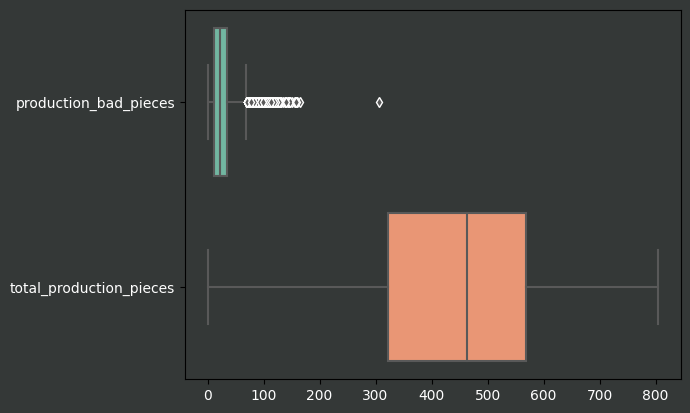

In [49]:
ax4 = sns.boxplot(nzero_df[production_cols], orient='h', palette='Set2', flierprops={"markeredgecolor": "white"})
ax4.set_facecolor("#343837")          # Inner color
ax4.figure.set_facecolor("#343837")    # Outer color
ax4.tick_params(labelcolor='white')

In [ ]:
prd_iqr = nzero_df['production_bad_pieces'].describe().loc['75%'] - nzero_df['production_bad_pieces'].describe().loc['25%']
prd_upprlim =  nzero_df['production_bad_pieces'].describe().loc['75%'] + 1.5*prd_iqr
prd_lwrlim = max(nzero_df['production_bad_pieces'].describe().loc['25%'] - 1.5*prd_iqr,0)

print(f"Interquartile Range: {prd_iqr} \tUpper Limit: {prd_upprlim} \tLower Limit: {prd_lwrlim}")

Interquartile Range: 23.0 	Upper Limit: 69.5 	Lower Limit: 0


In [87]:
nzero_df[nzero_df['production_bad_pieces'] > 69.5].drop(['production_datetime', 'production_shift'],axis=1).groupby('production_year').count()

,production_good_pieces,production_bad_pieces,production_target_pieces,machine_running_time,machine_planned_downtime,machine_idle_time,machine_breakdown_time,machine_availability_percent,production_performance_percent,production_quality_percent,overall_equipement_effectiveness_percent,production_month,total_production_pieces,total_no_scheduled_downtime
production_year,,,,,,,,,,,,,,
2024,219,219,219,219,219,219,219,219,219,219,219,219,219,219
2025,131,131,131,131,131,131,131,131,131,131,131,131,131,131
2026,113,113,113,113,113,113,113,113,113,113,113,113,113,113


In [ ]:
nzero_df.drop(['production_datetime', 'production_shift'],axis=1).describe()

,production_good_pieces,production_bad_pieces,production_target_pieces,machine_running_time,machine_planned_downtime,machine_idle_time,machine_breakdown_time,machine_availability_percent,production_performance_percent,production_quality_percent,overall_equipement_effectiveness_percent,production_year,production_month,total_production_pieces,total_no_scheduled_downtime
count,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000
mean,405.420692,26.395066,455.688064,2430.653705,774.044903,223.267967,169.914604,91.494786,97.725600,93.233346,85.832786,2024.980661,6.202865,431.815758,2823.836275
std,159.283620,19.925480,139.732893,933.386711,863.604793,350.124557,379.909072,19.480254,79.298312,6.678487,64.889782,0.813092,3.340464,165.948959,864.644485
min,0.000000,0.000000,0.650000,0.000000,0.000000,0.000000,0.000000,0.000000,0.170000,0.000000,0.000000,2024.000000,1.000000,1.000000,4.000000
25%,300.000000,12.000000,386.940000,1812.000000,0.000000,0.000000,0.000000,93.870000,83.490000,91.570000,70.470000,2024.000000,3.000000,323.000000,2399.000000
50%,432.000000,22.000000,483.870000,2546.000000,600.000000,53.000000,27.000000,98.780000,100.000000,94.660000,90.460000,2025.000000,6.000000,464.000000,3000.000000
75%,536.000000,35.000000,580.650000,3223.000000,1201.000000,325.000000,143.000000,100.000000,110.390000,96.770000,103.510000,2026.000000,9.000000,569.000000,3600.000000
max,780.000000,306.000000,805.000000,3600.000000,3596.000000,3489.000000,3544.000000,100.000000,7585.880000,100.000000,5397.650000,2026.000000,12.000000,805.000000,3601.000000


In [89]:
nzero_df[nzero_df['production_bad_pieces'] <= 69.5].drop(['production_datetime', 'production_shift'],axis=1).describe()

,production_good_pieces,production_bad_pieces,production_target_pieces,machine_running_time,machine_planned_downtime,machine_idle_time,machine_breakdown_time,machine_availability_percent,production_performance_percent,production_quality_percent,overall_equipement_effectiveness_percent,production_year,production_month,total_production_pieces,total_no_scheduled_downtime
count,12102.000000,12102.000000,12102.000000,12102.000000,12102.000000,12102.000000,12102.000000,12102.000000,12102.000000,12102.000000,12102.000000,12102.000000,12102.000000,12102.000000,12102.000000
mean,403.966865,24.041233,452.794062,2410.131416,791.842555,224.518757,171.308792,91.408661,97.603363,93.641782,86.082469,2024.988680,6.156668,428.008098,2805.958965
std,160.893178,15.630866,140.891834,938.375408,870.868603,353.358889,384.265710,19.606451,80.713403,6.321929,65.954982,0.811935,3.333078,166.756066,871.894232
min,0.000000,0.000000,0.650000,0.000000,0.000000,0.000000,0.000000,0.000000,0.170000,0.000000,0.000000,2024.000000,1.000000,1.000000,4.000000
25%,296.000000,12.000000,386.940000,1795.000000,0.000000,0.000000,0.000000,93.760000,83.087500,92.070000,70.437500,2024.000000,3.000000,317.000000,2399.000000
50%,429.000000,21.000000,483.870000,2500.000000,600.000000,52.000000,27.000000,98.800000,99.935000,94.830000,90.785000,2025.000000,6.000000,458.000000,3000.000000
75%,537.000000,34.000000,580.650000,3206.750000,1201.000000,326.000000,143.000000,100.000000,110.390000,96.840000,103.840000,2026.000000,9.000000,567.000000,3600.000000
max,780.000000,69.000000,805.000000,3600.000000,3596.000000,3489.000000,3544.000000,100.000000,7585.880000,100.000000,5397.650000,2026.000000,12.000000,805.000000,3601.000000


#### Production Data Distribution

c:\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


Text(0.5, 1.0, 'PRODUCED BAD PIECES')

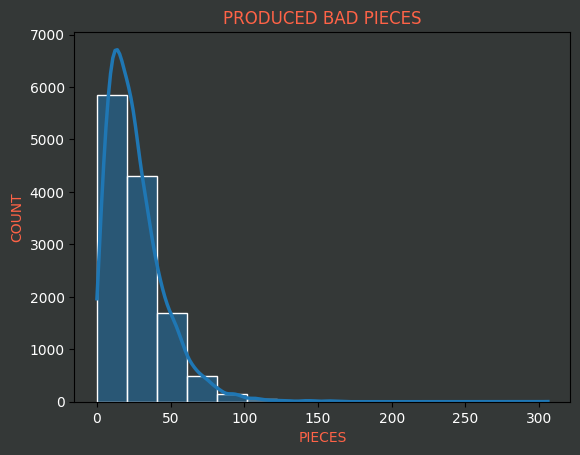

In [39]:
ax7 = sns.histplot(data=nzero_df, x="production_bad_pieces", bins=15, kde=True, edgecolor='white', line_kws={"color": 'white', "linewidth": 2.5})
ax7.set_facecolor("#343837")          # Inner color
ax7.figure.set_facecolor("#343837")    # Outer color
ax7.tick_params(labelcolor='white')
ax7.set_xlabel('PIECES', color='tomato')
ax7.set_ylabel('COUNT', color='tomato')
ax7.set_title('PRODUCED BAD PIECES', color='tomato')

c:\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


Text(0.5, 1.0, 'TOTAL PRODUCED PIECES')

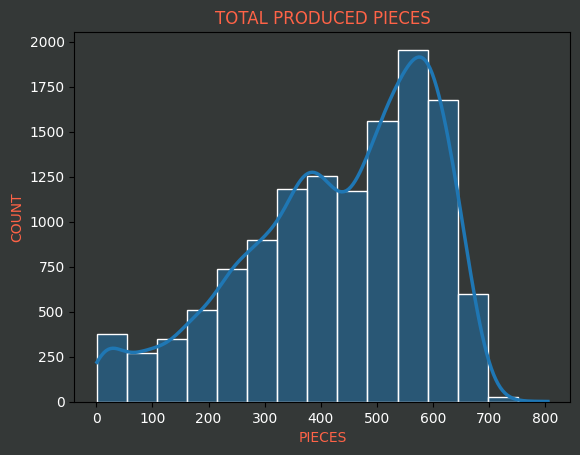

In [41]:
ax8 = sns.histplot(data=nzero_df, x="total_production_pieces", bins=15, kde=True, edgecolor='white', line_kws={"color": 'white', "linewidth": 2.5})
ax8.set_facecolor("#343837")          # Inner color
ax8.figure.set_facecolor("#343837")    # Outer color
ax8.tick_params(labelcolor='white')
ax8.set_xlabel('PIECES', color='tomato')
ax8.set_ylabel('COUNT', color='tomato')
ax8.set_title('TOTAL PRODUCED PIECES', color='tomato')

#### 5-number Machine-Time Summary

In [50]:
machine_cols = ['machine_breakdown_time', 'total_no_scheduled_downtime']

nzero_df[machine_cols].describe()

,machine_breakdown_time,total_no_scheduled_downtime
count,12565.000000,12565.000000
mean,169.914604,2823.836275
std,379.909072,864.644485
min,0.000000,4.000000
25%,0.000000,2399.000000
50%,27.000000,3000.000000
75%,143.000000,3600.000000
max,3544.000000,3601.000000


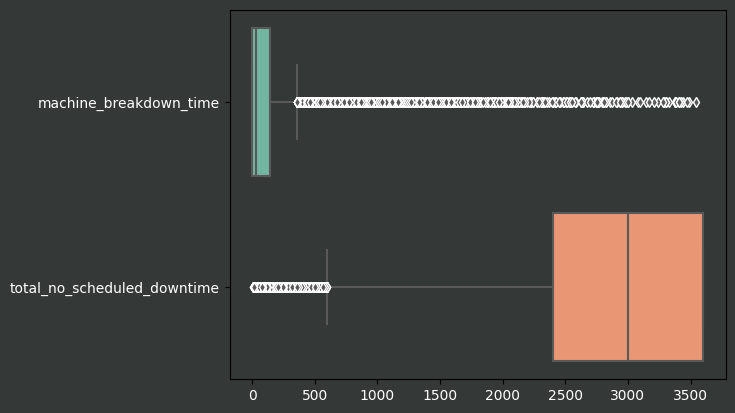

In [51]:
ax5 = sns.boxplot(nzero_df[machine_cols], orient='h', palette='Set2', flierprops={"markeredgecolor": "white"})
ax5.set_facecolor("#343837")          # Inner color
ax5.figure.set_facecolor("#343837")    # Outer color
ax5.tick_params(labelcolor='white')

In [108]:
mac_iqr = nzero_df['machine_breakdown_time'].describe().loc['75%'] - nzero_df['machine_breakdown_time'].describe().loc['25%']
mac_upprlim =  nzero_df['machine_breakdown_time'].describe().loc['75%'] + 1.5*mac_iqr
mac_lwrlim = max(nzero_df['machine_breakdown_time'].describe().loc['25%'] - 1.5*mac_iqr,0)

print(f"Interquartile Range: {mac_iqr} \tUpper Limit: {mac_upprlim} \tLower Limit: {mac_lwrlim}")

Interquartile Range: 143.0 	Upper Limit: 357.5 	Lower Limit: 0


In [109]:
nzero_df[nzero_df['machine_breakdown_time'] > 357.5].drop(['production_datetime', 'production_shift'],axis=1).groupby('production_year').count()

,production_good_pieces,production_bad_pieces,production_target_pieces,machine_running_time,machine_planned_downtime,machine_idle_time,machine_breakdown_time,machine_availability_percent,production_performance_percent,production_quality_percent,overall_equipement_effectiveness_percent,production_month,total_production_pieces,total_no_scheduled_downtime
production_year,,,,,,,,,,,,,,
2024,523,523,523,523,523,523,523,523,523,523,523,523,523,523
2025,535,535,535,535,535,535,535,535,535,535,535,535,535,535
2026,562,562,562,562,562,562,562,562,562,562,562,562,562,562


In [110]:
nzero_df.drop(['production_datetime', 'production_shift'],axis=1).describe()

,production_good_pieces,production_bad_pieces,production_target_pieces,machine_running_time,machine_planned_downtime,machine_idle_time,machine_breakdown_time,machine_availability_percent,production_performance_percent,production_quality_percent,overall_equipement_effectiveness_percent,production_year,production_month,total_production_pieces,total_no_scheduled_downtime
count,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000,12565.000000
mean,405.420692,26.395066,455.688064,2430.653705,774.044903,223.267967,169.914604,91.494786,97.725600,93.233346,85.832786,2024.980661,6.202865,431.815758,2823.836275
std,159.283620,19.925480,139.732893,933.386711,863.604793,350.124557,379.909072,19.480254,79.298312,6.678487,64.889782,0.813092,3.340464,165.948959,864.644485
min,0.000000,0.000000,0.650000,0.000000,0.000000,0.000000,0.000000,0.000000,0.170000,0.000000,0.000000,2024.000000,1.000000,1.000000,4.000000
25%,300.000000,12.000000,386.940000,1812.000000,0.000000,0.000000,0.000000,93.870000,83.490000,91.570000,70.470000,2024.000000,3.000000,323.000000,2399.000000
50%,432.000000,22.000000,483.870000,2546.000000,600.000000,53.000000,27.000000,98.780000,100.000000,94.660000,90.460000,2025.000000,6.000000,464.000000,3000.000000
75%,536.000000,35.000000,580.650000,3223.000000,1201.000000,325.000000,143.000000,100.000000,110.390000,96.770000,103.510000,2026.000000,9.000000,569.000000,3600.000000
max,780.000000,306.000000,805.000000,3600.000000,3596.000000,3489.000000,3544.000000,100.000000,7585.880000,100.000000,5397.650000,2026.000000,12.000000,805.000000,3601.000000


In [112]:
nzero_df[nzero_df['machine_breakdown_time'] <= 357.5].drop(['production_datetime', 'production_shift'],axis=1).describe()

,production_good_pieces,production_bad_pieces,production_target_pieces,machine_running_time,machine_planned_downtime,machine_idle_time,machine_breakdown_time,machine_availability_percent,production_performance_percent,production_quality_percent,overall_equipement_effectiveness_percent,production_year,production_month,total_production_pieces,total_no_scheduled_downtime
count,10945.000000,10945.000000,10945.000000,10945.000000,10945.000000,10945.000000,10945.000000,10945.000000,10945.000000,10945.000000,10945.000000,10945.000000,10945.000000,10945.000000,10945.000000
mean,423.995706,26.576153,449.335869,2528.029219,813.406962,201.576793,54.636820,94.918717,103.231605,93.752069,92.429302,2024.974235,6.143079,450.571859,2784.242832
std,153.175375,20.003131,143.681558,906.693334,887.799544,335.353717,80.385343,16.935331,82.913735,5.491935,66.450165,0.812162,3.365252,159.960074,888.856810
min,0.000000,0.000000,0.650000,0.000000,0.000000,0.000000,0.000000,0.000000,0.210000,0.000000,0.000000,2024.000000,1.000000,1.000000,4.000000
25%,327.000000,12.000000,383.550000,1996.000000,0.000000,0.000000,0.000000,96.530000,90.240000,92.090000,79.340000,2024.000000,3.000000,350.000000,2378.000000
50%,459.000000,22.000000,483.870000,2691.000000,600.000000,33.000000,11.000000,99.390000,101.610000,94.880000,93.830000,2025.000000,6.000000,490.000000,3000.000000
75%,546.000000,36.000000,580.650000,3339.000000,1218.000000,283.000000,86.000000,100.000000,112.290000,96.880000,105.360000,2026.000000,9.000000,579.000000,3600.000000
max,780.000000,306.000000,805.000000,3600.000000,3596.000000,3489.000000,357.000000,100.000000,7585.880000,100.000000,5397.650000,2026.000000,12.000000,805.000000,3601.000000


#### Machine-time Data Distribution

c:\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


Text(0.5, 1.0, 'MACHINE BREAKDOWN TIME')

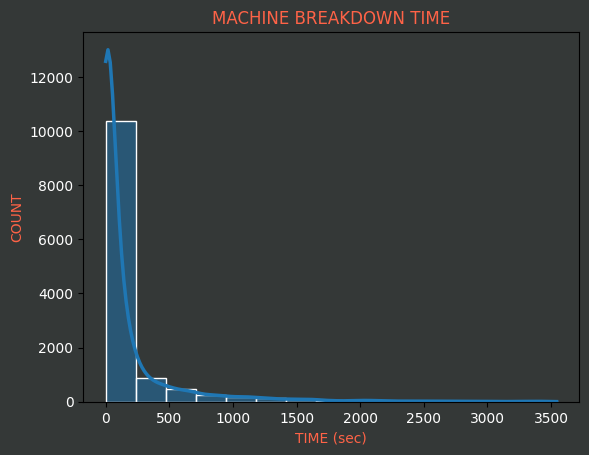

In [46]:
ax11 = sns.histplot(data=nzero_df, x="machine_breakdown_time", bins=15, kde=True, edgecolor='white', line_kws={"color": 'white', "linewidth": 2.5})
ax11.set_facecolor("#343837")          # Inner color
ax11.figure.set_facecolor("#343837")    # Outer color
ax11.tick_params(labelcolor='white')
ax11.set_xlabel('TIME (sec)', color='tomato')
ax11.set_ylabel('COUNT', color='tomato')
ax11.set_title('MACHINE BREAKDOWN TIME', color='tomato')

c:\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


Text(0.5, 1.0, 'TOTAL NO-SCHEDULED DOWNTIME')

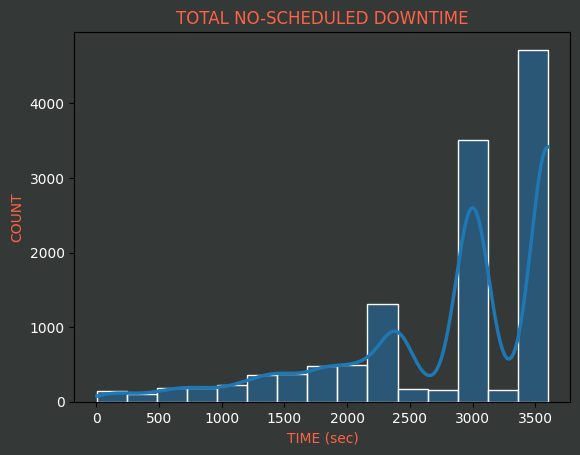

In [47]:
ax12 = sns.histplot(data=nzero_df, x="total_no_scheduled_downtime", bins=15, kde=True, edgecolor='white', line_kws={"color": 'white', "linewidth": 2.5})
ax12.set_facecolor("#343837")          # Inner color
ax12.figure.set_facecolor("#343837")    # Outer color
ax12.tick_params(labelcolor='white')
ax12.set_xlabel('TIME (sec)', color='tomato')
ax12.set_ylabel('COUNT', color='tomato')
ax12.set_title('TOTAL NO-SCHEDULED DOWNTIME', color='tomato')

### Production Magnitude Analysis

Text(0.5, 1.0, 'PIECES PRODUCED BY MONTH')

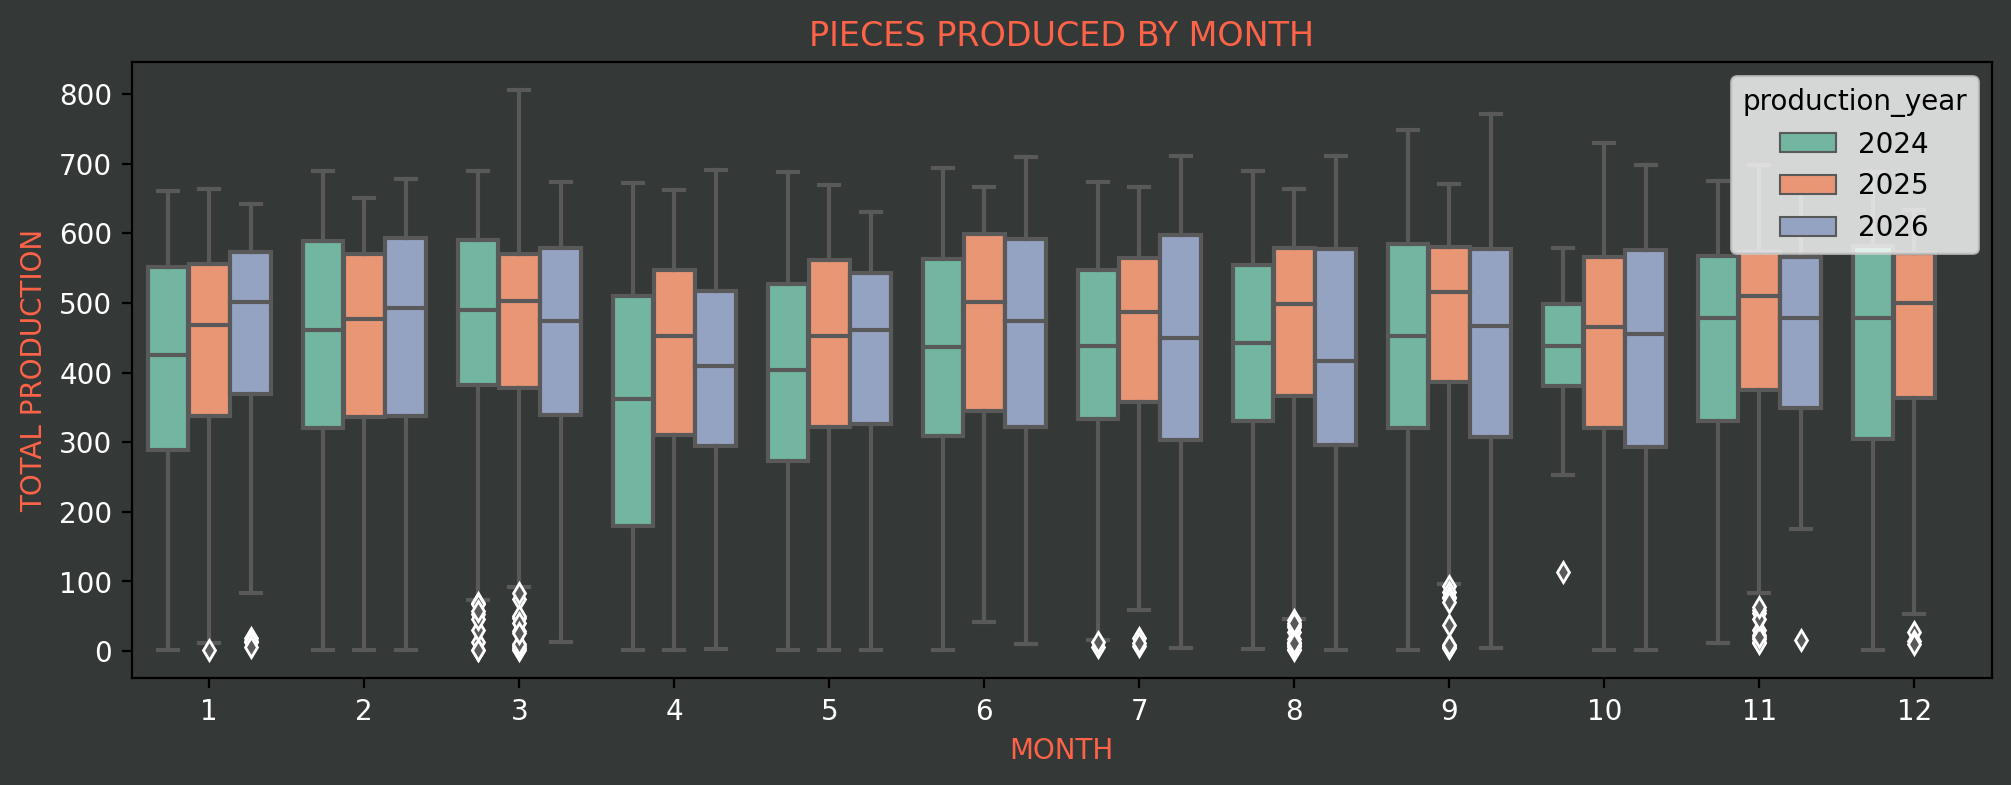

In [100]:
plt.figure(figsize=(12,4), dpi=200)
ax2 = sns.boxplot(nzero_df, x='production_month', y='total_production_pieces', hue='production_year', palette='Set2', flierprops={"markeredgecolor": "white"})

ax2.set_facecolor("#343837")          # Inner color
ax2.figure.set_facecolor("#343837")    # Outer color
ax2.set_xlabel('MONTH', color='tomato')
ax2.set_ylabel('TOTAL PRODUCTION', color='tomato')
ax2.tick_params(labelcolor='white')
ax2.set_title('PIECES PRODUCED BY MONTH', color='tomato')
#plt.ylim(300, 550)

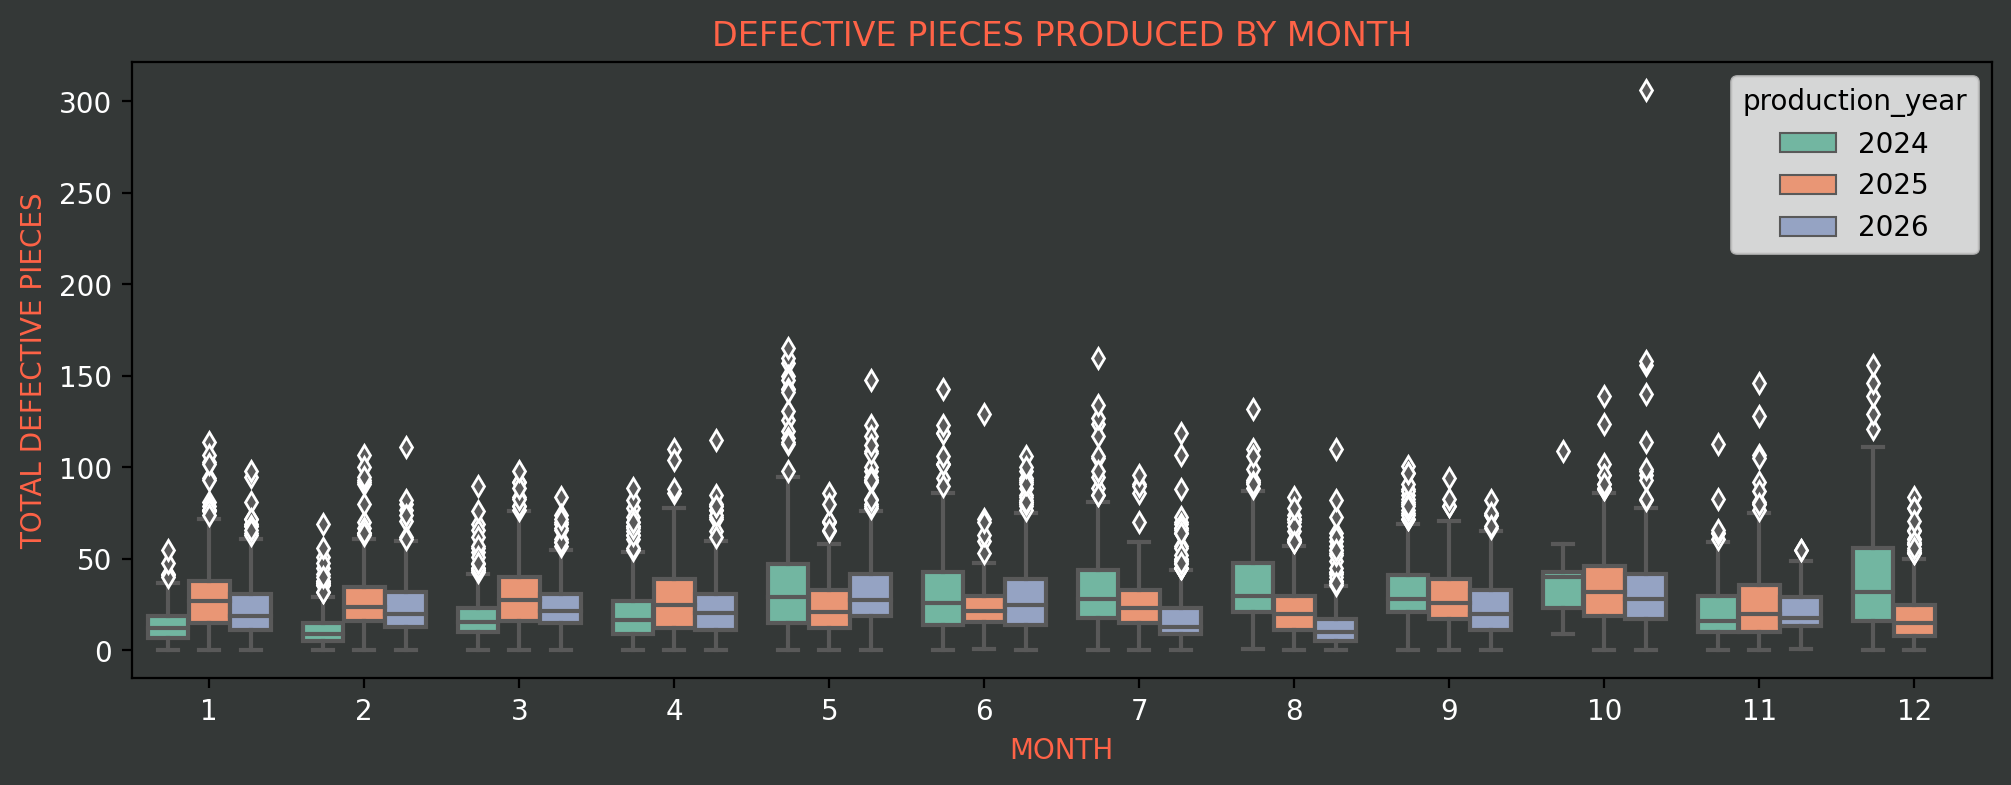

In [102]:
plt.figure(figsize=(12,4), dpi=200)
ax3 = sns.boxplot(nzero_df, x='production_month', y='production_bad_pieces', hue='production_year', palette='Set2', flierprops={"markeredgecolor": "white"})

ax3.set_facecolor("#343837")          # Inner color
ax3.figure.set_facecolor("#343837")    # Outer color
ax3.set_xlabel('MONTH', color='tomato')
ax3.set_ylabel('TOTAL DEFECTIVE PIECES', color='tomato')
ax3.set_title('DEFECTIVE PIECES PRODUCED BY MONTH', color='tomato')
ax3.tick_params(labelcolor='white')
#plt.ylim(0, 65)

Text(0.5, 1.0, 'QUALITY PCT BY MONTH')

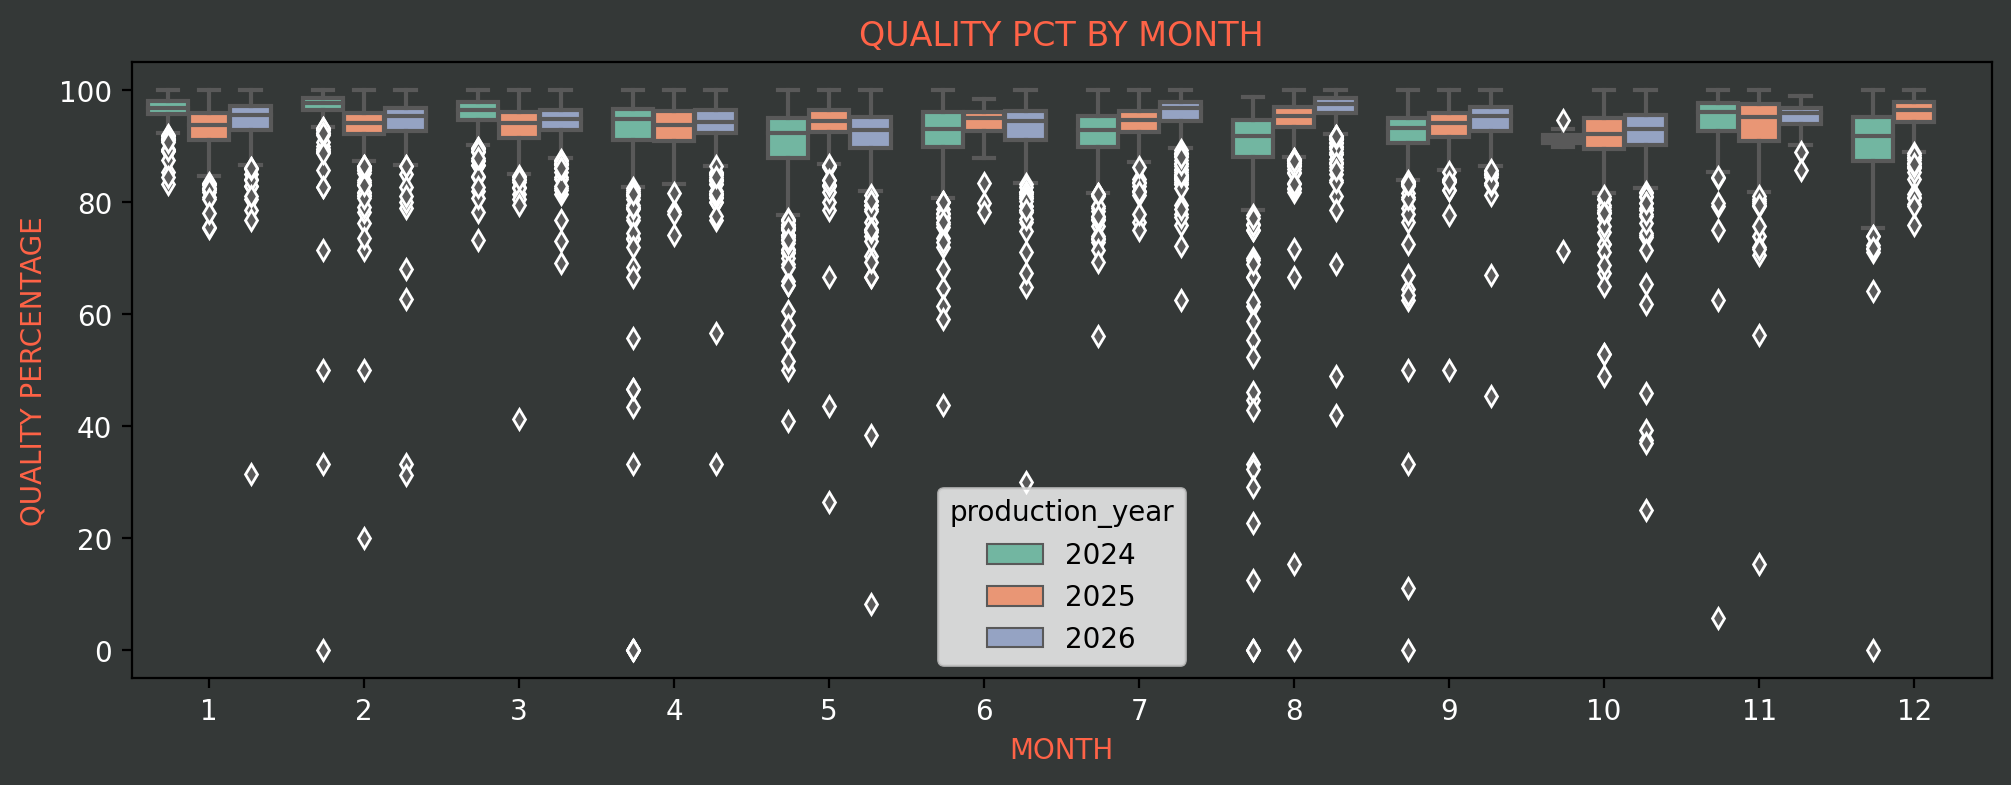

In [103]:
plt.figure(figsize=(12,4), dpi=200)
ax12 = sns.boxplot(nzero_df, x='production_month', y='production_quality_percent', hue='production_year', palette='Set2', flierprops={"markeredgecolor": "white"})

ax12.set_facecolor("#343837")          # Inner color
ax12.figure.set_facecolor("#343837")    # Outer color
ax12.set_xlabel('MONTH', color='tomato')
ax12.set_ylabel('QUALITY PERCENTAGE', color='tomato')
ax12.tick_params(labelcolor='white')
ax12.set_title('QUALITY PCT BY MONTH', color='tomato')
#plt.ylim(80, 100)

c:\Python311\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
c:\Python311\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


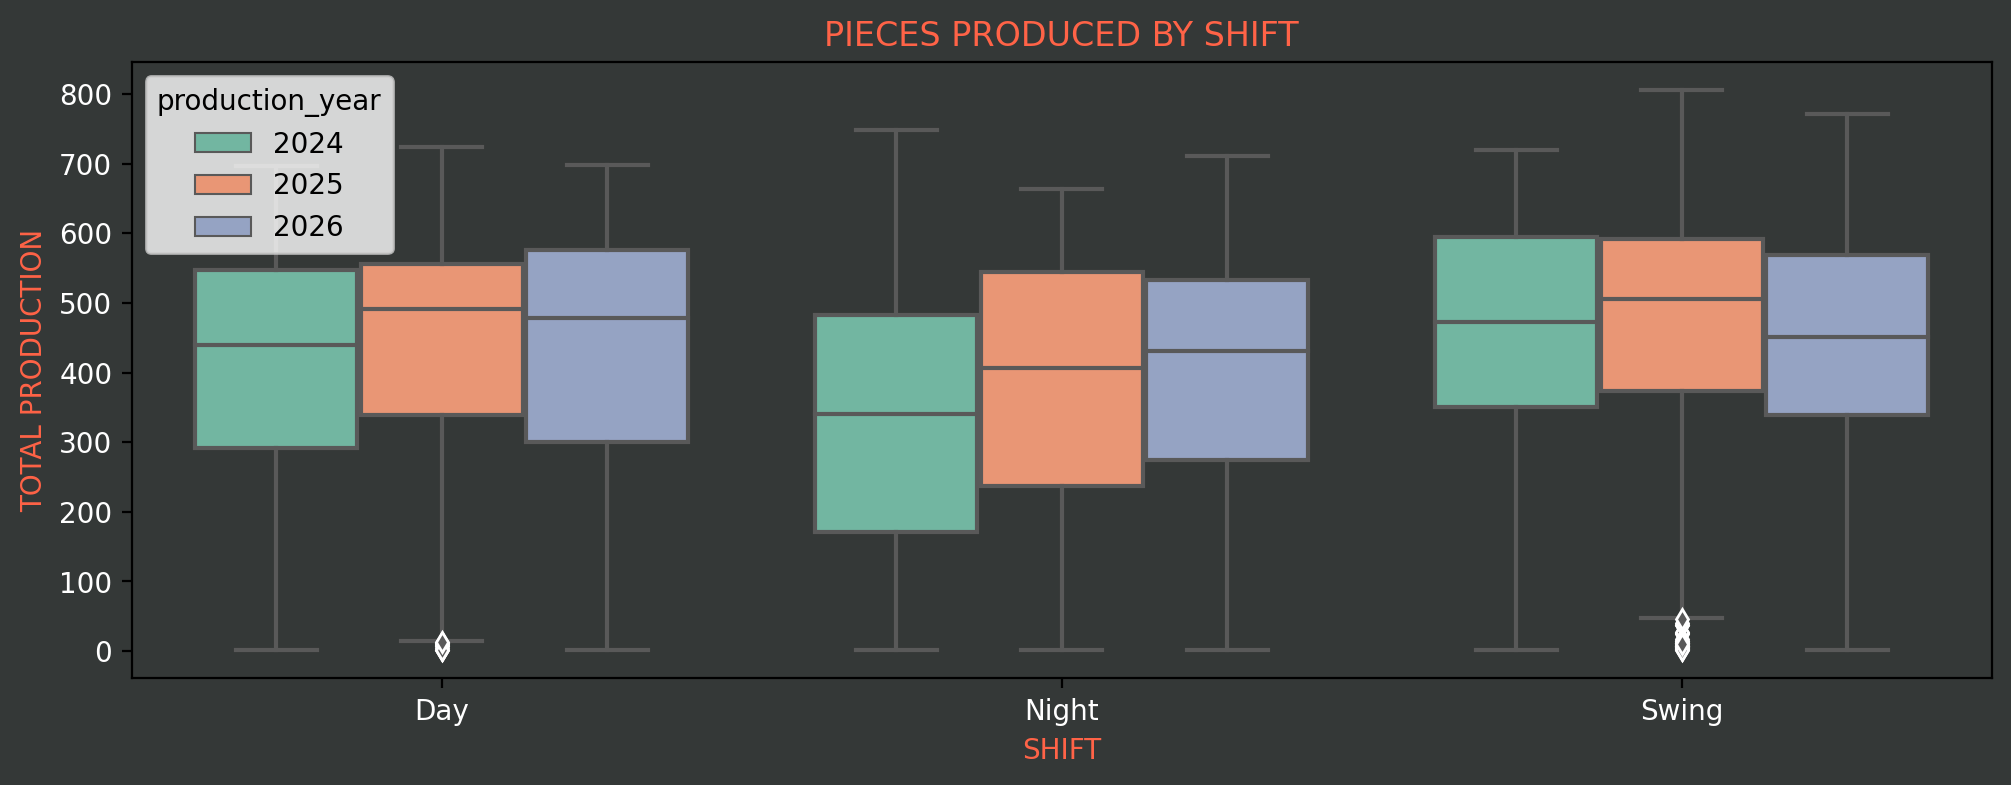

In [104]:
plt.figure(figsize=(12,4), dpi=200)
ax = sns.boxplot(nzero_df, x='production_shift', y='total_production_pieces', hue='production_year', palette='Set2', flierprops={"markeredgecolor": "white"})

ax.set_facecolor("#343837")          # Inner color
ax.figure.set_facecolor("#343837")    # Outer color
ax.set_xlabel('SHIFT', color='tomato')
ax.set_ylabel('TOTAL PRODUCTION', color='tomato')
ax.set_title('PIECES PRODUCED BY SHIFT', color='tomato')
ax.tick_params(labelcolor='white')
#plt.ylim(300, 500)

c:\Python311\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
c:\Python311\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


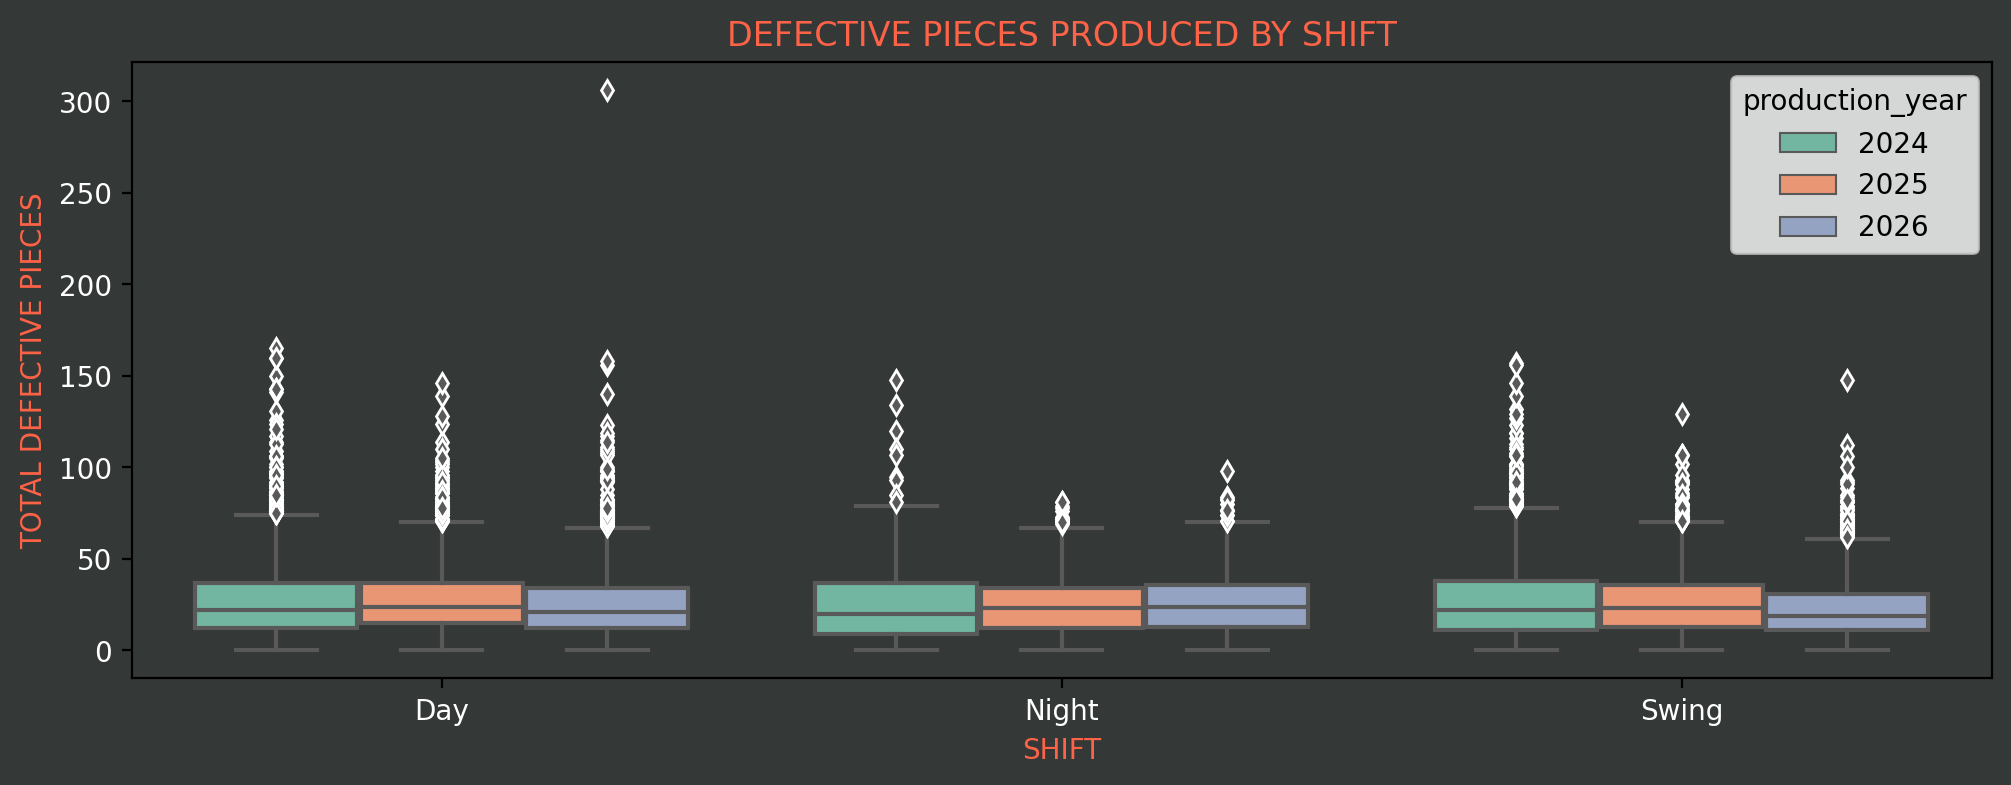

In [105]:
plt.figure(figsize=(12,4), dpi=200)
ax1 = sns.boxplot(nzero_df, x='production_shift', y='production_bad_pieces', hue='production_year', palette='Set2', flierprops={"markeredgecolor": "white"})

ax1.set_facecolor("#343837")          # Inner color
ax1.figure.set_facecolor("#343837")    # Outer color
ax1.set_xlabel('SHIFT', color='tomato')
ax1.set_ylabel('TOTAL DEFECTIVE PIECES', color='tomato')
ax1.set_title('DEFECTIVE PIECES PRODUCED BY SHIFT', color='tomato')
ax1.tick_params(labelcolor='white')
#plt.ylim(20, 30)

c:\Python311\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
c:\Python311\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


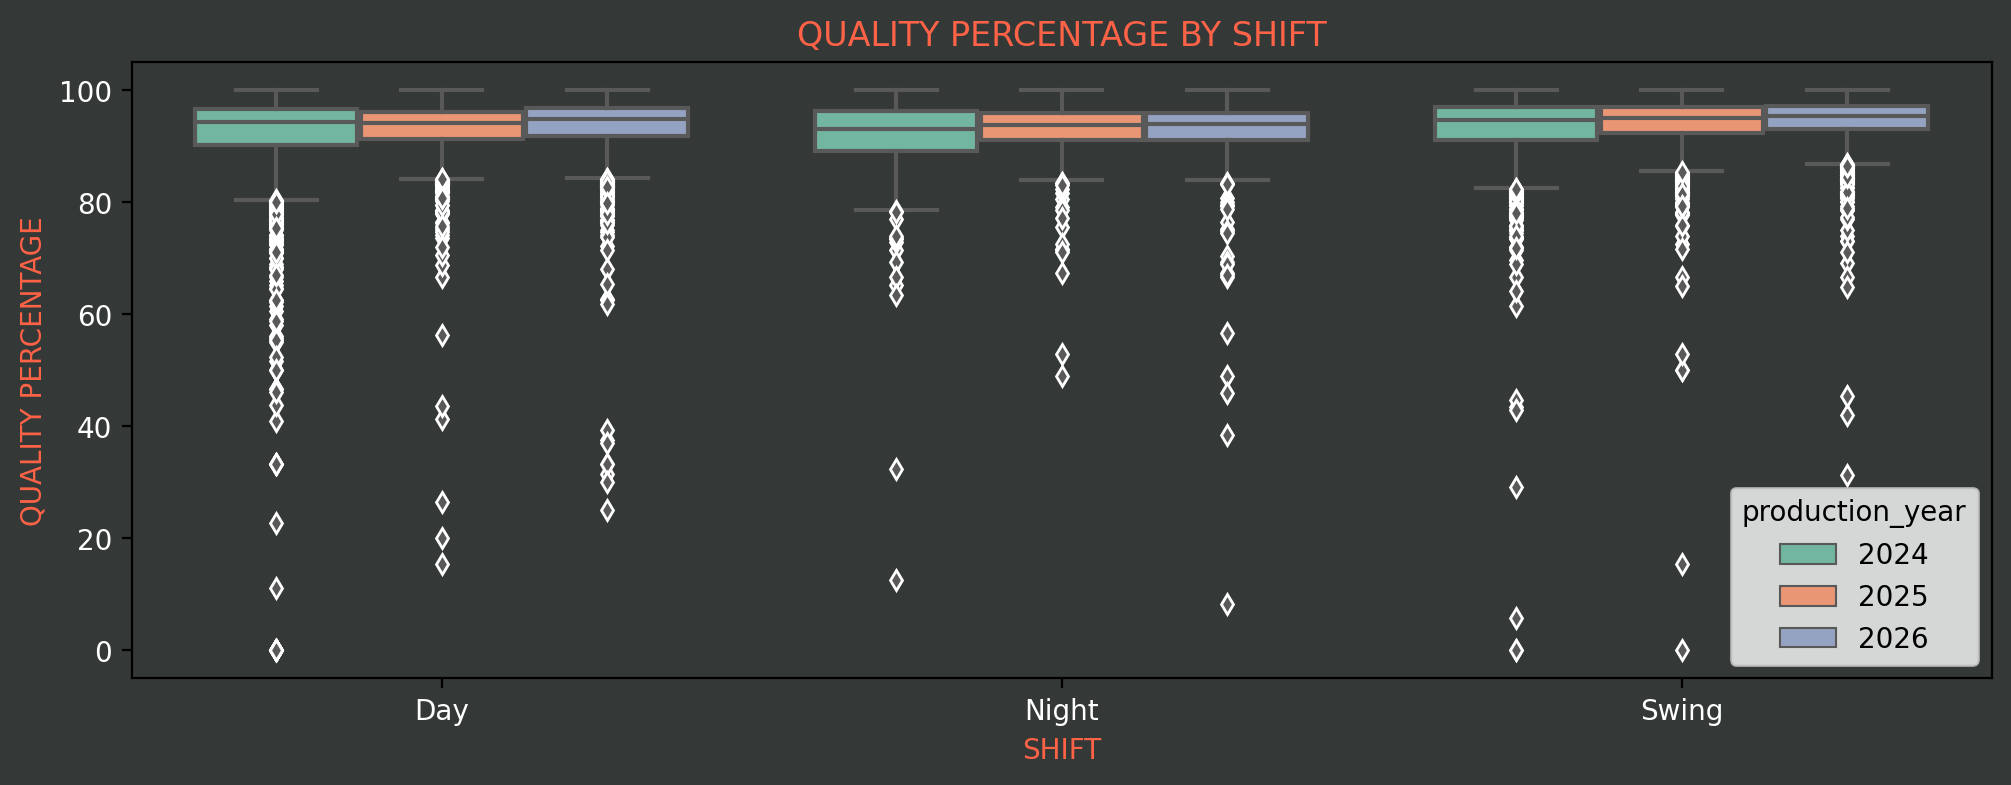

In [106]:
plt.figure(figsize=(12,4), dpi=200)
ax13 = sns.boxplot(nzero_df, x='production_shift', y='production_quality_percent', hue='production_year', palette='Set2', flierprops={"markeredgecolor": "white"})

ax13.set_facecolor("#343837")          # Inner color
ax13.figure.set_facecolor("#343837")    # Outer color
ax13.set_xlabel('SHIFT', color='tomato')
ax13.set_ylabel('QUALITY PERCENTAGE', color='tomato')
ax13.set_title('QUALITY PERCENTAGE BY SHIFT', color='tomato')
ax13.tick_params(labelcolor='white')
#plt.ylim(80, 100)

#### Time Analysis

In [ ]:
monthly_prd_bad_pcs_df = nzero_df.groupby(pd.Grouper(key='production_datetime', freq='MS'))['production_bad_pieces'].sum()

c:\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


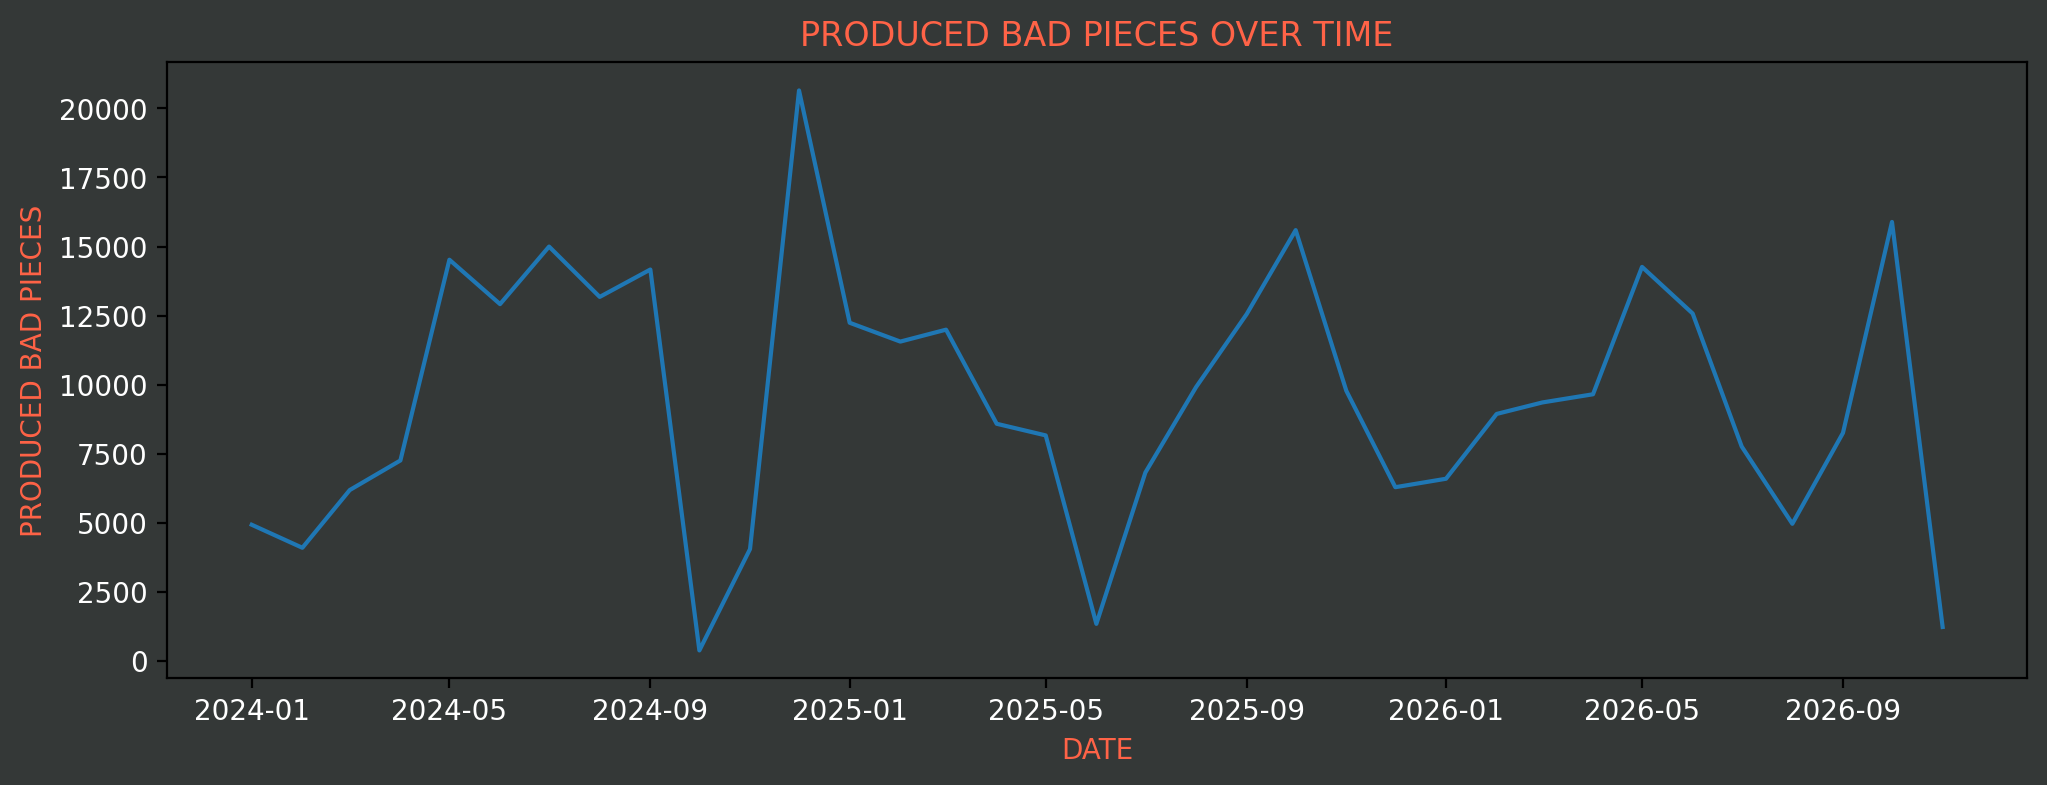

In [ ]:
plt.figure(figsize=(12,4), dpi=200)
ax19 = sns.lineplot(monthly_prd_bad_pcs_df, x=monthly_prd_bad_pcs_df.index, y=monthly_prd_bad_pcs_df)

ax19.set_facecolor("#343837")          # Inner color
ax19.figure.set_facecolor("#343837")    # Outer color
ax19.set_xlabel('DATE', color='tomato')
ax19.set_ylabel('PRODUCED BAD PIECES', color='tomato')
ax19.set_title('PRODUCED BAD PIECES OVER TIME', color='tomato')
ax19.tick_params(labelcolor='white')

### Machine-time Magnitude Analysis

Text(0.5, 1.0, 'NO-SCHEDULED DOWNTIME BY MONTH')

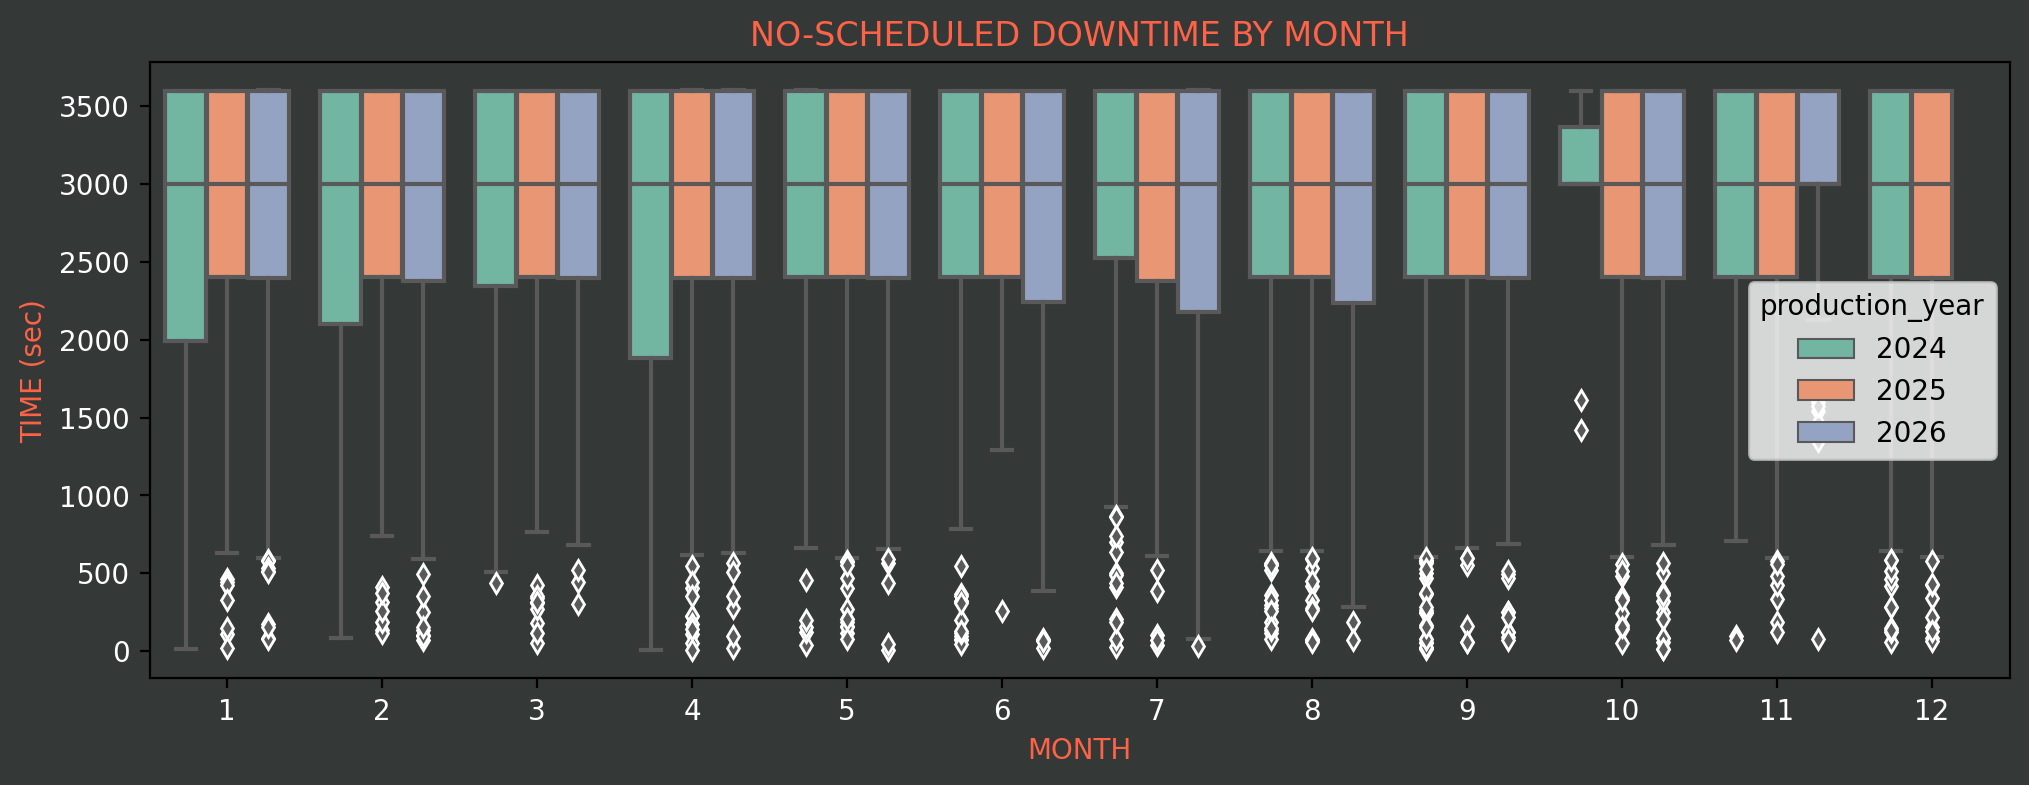

In [115]:
plt.figure(figsize=(12,4), dpi=200)
ax15 = sns.boxplot(nzero_df, x='production_month', y='total_no_scheduled_downtime', hue='production_year', palette='Set2', flierprops={"markeredgecolor": "white"})

ax15.set_facecolor("#343837")          # Inner color
ax15.figure.set_facecolor("#343837")    # Outer color
ax15.set_xlabel('MONTH', color='tomato')
ax15.set_ylabel('TIME (sec)', color='tomato')
ax15.tick_params(labelcolor='white')
ax15.set_title('NO-SCHEDULED DOWNTIME BY MONTH', color='tomato')
#plt.ylim(300, 550)

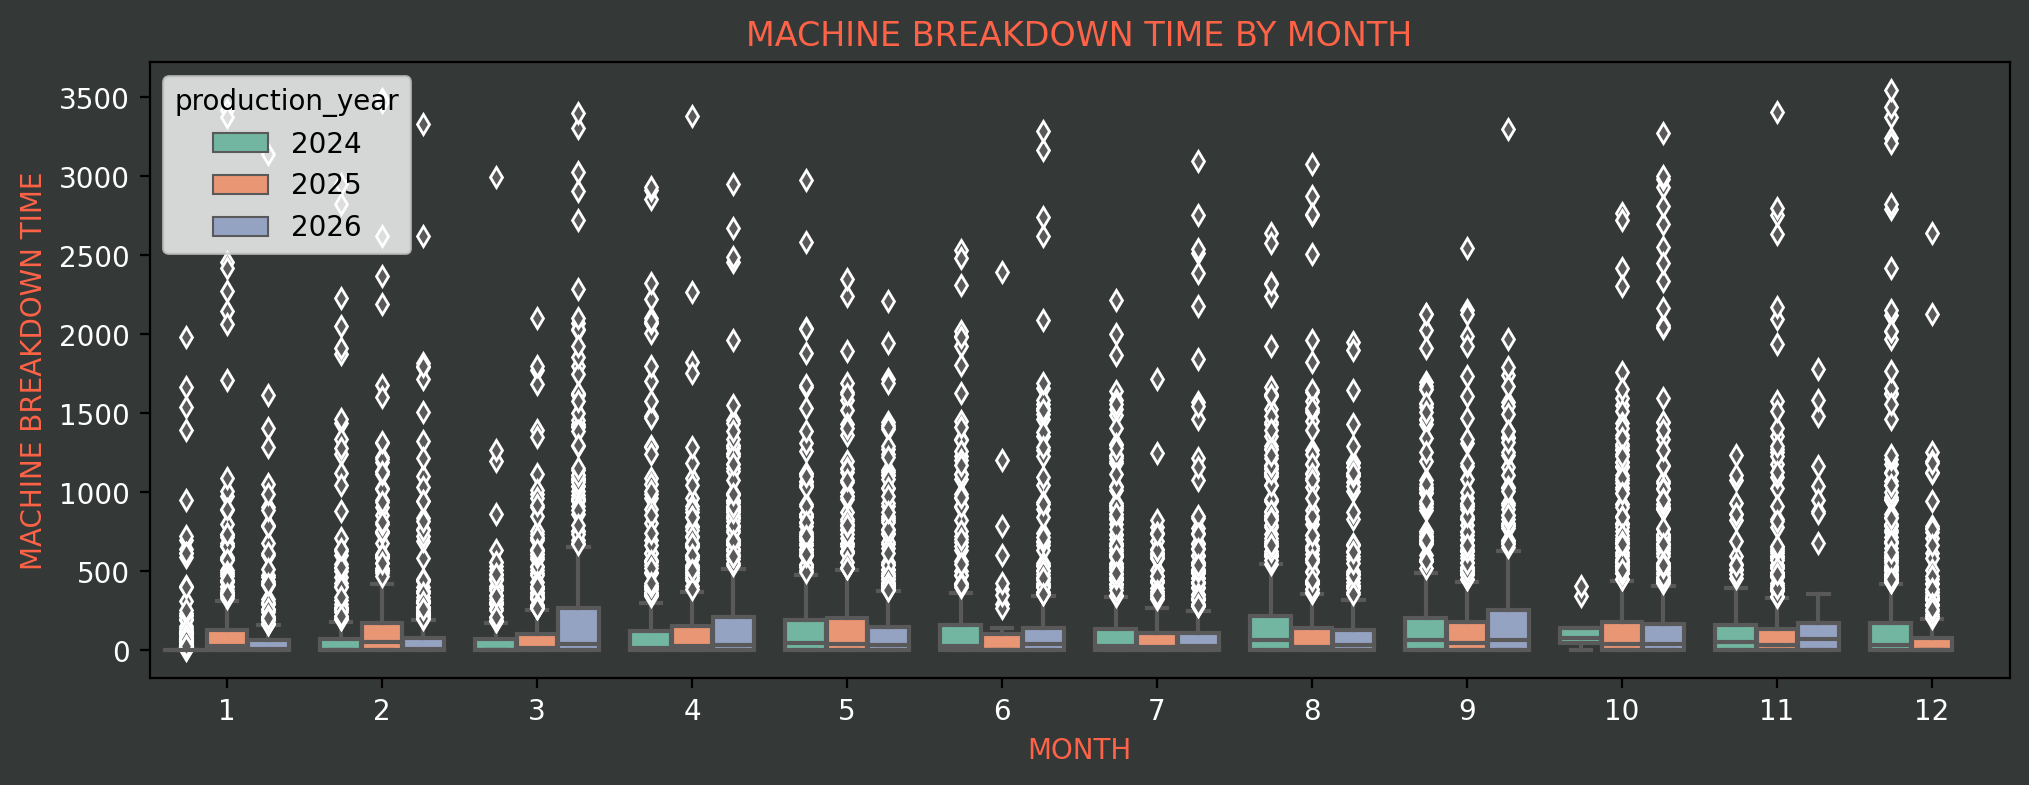

In [116]:
plt.figure(figsize=(12,4), dpi=200)
ax15 = sns.boxplot(nzero_df, x='production_month', y='machine_breakdown_time', hue='production_year', palette='Set2', flierprops={"markeredgecolor": "white"})

ax15.set_facecolor("#343837")          # Inner color
ax15.figure.set_facecolor("#343837")    # Outer color
ax15.set_xlabel('MONTH', color='tomato')
ax15.set_ylabel('MACHINE BREAKDOWN TIME', color='tomato')
ax15.set_title('MACHINE BREAKDOWN TIME BY MONTH', color='tomato')
ax15.tick_params(labelcolor='white')
#plt.ylim(0, 65)

Text(0.5, 1.0, 'AVAILABILITY PCT BY MONTH')

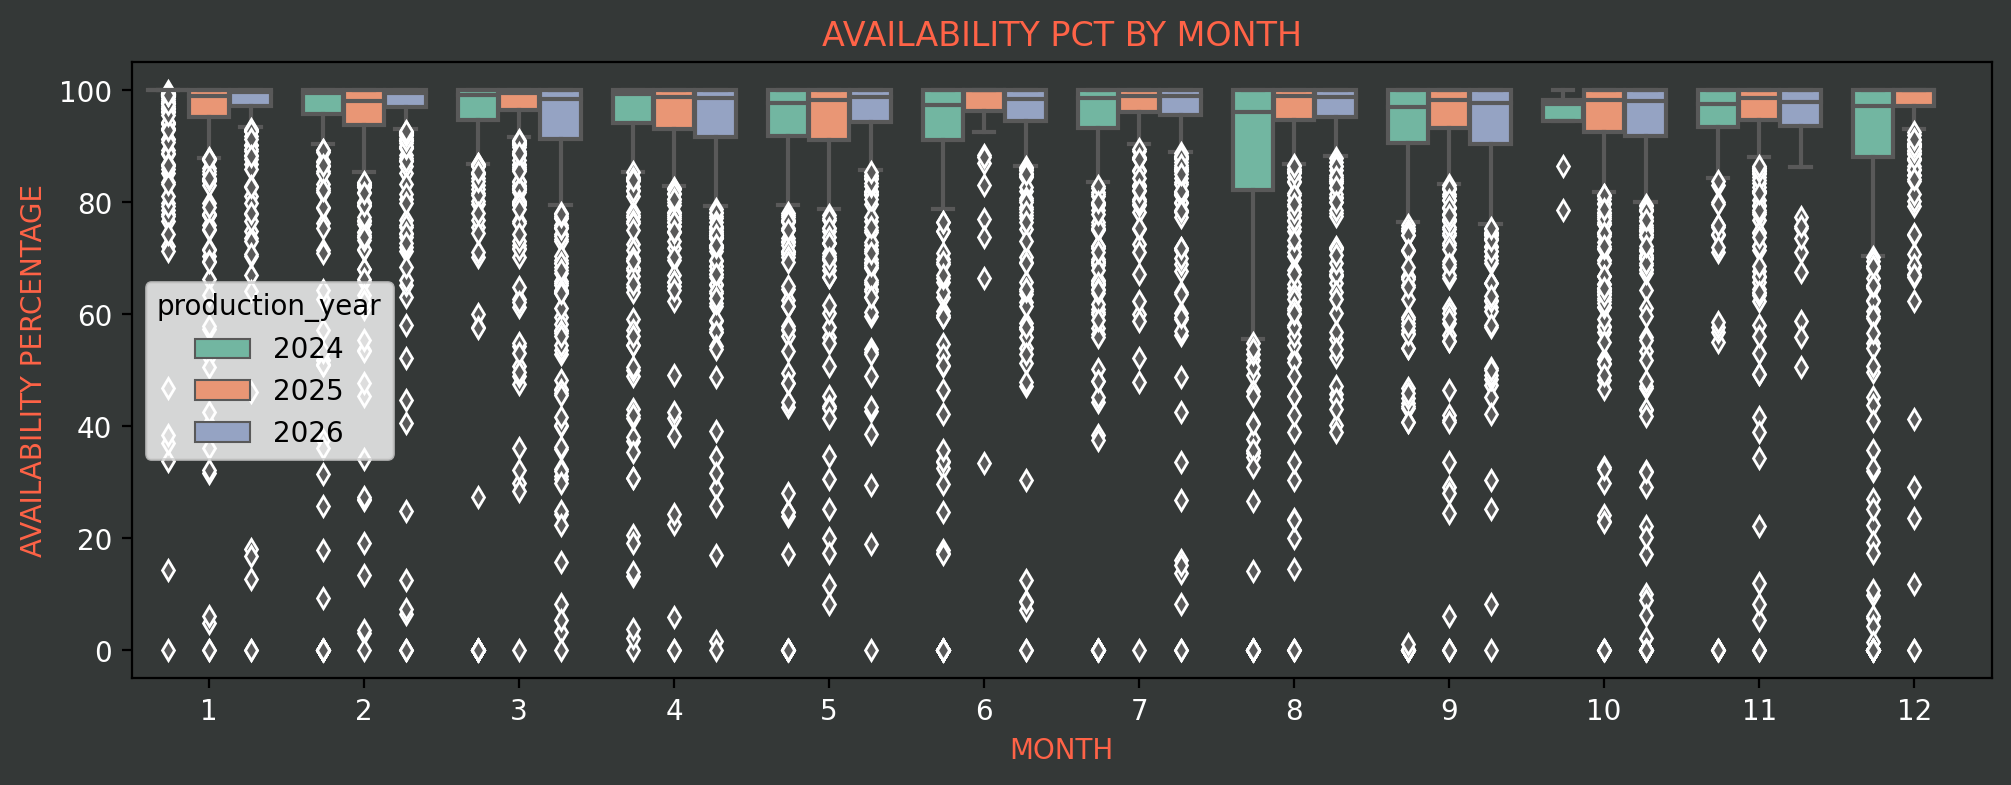

In [117]:
plt.figure(figsize=(12,4), dpi=200)
ax16 = sns.boxplot(nzero_df, x='production_month', y='machine_availability_percent', hue='production_year', palette='Set2', flierprops={"markeredgecolor": "white"})

ax16.set_facecolor("#343837")          # Inner color
ax16.figure.set_facecolor("#343837")    # Outer color
ax16.set_xlabel('MONTH', color='tomato')
ax16.set_ylabel('AVAILABILITY PERCENTAGE', color='tomato')
ax16.tick_params(labelcolor='white')
ax16.set_title('AVAILABILITY PCT BY MONTH', color='tomato')
#plt.ylim(80, 100)

c:\Python311\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
c:\Python311\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


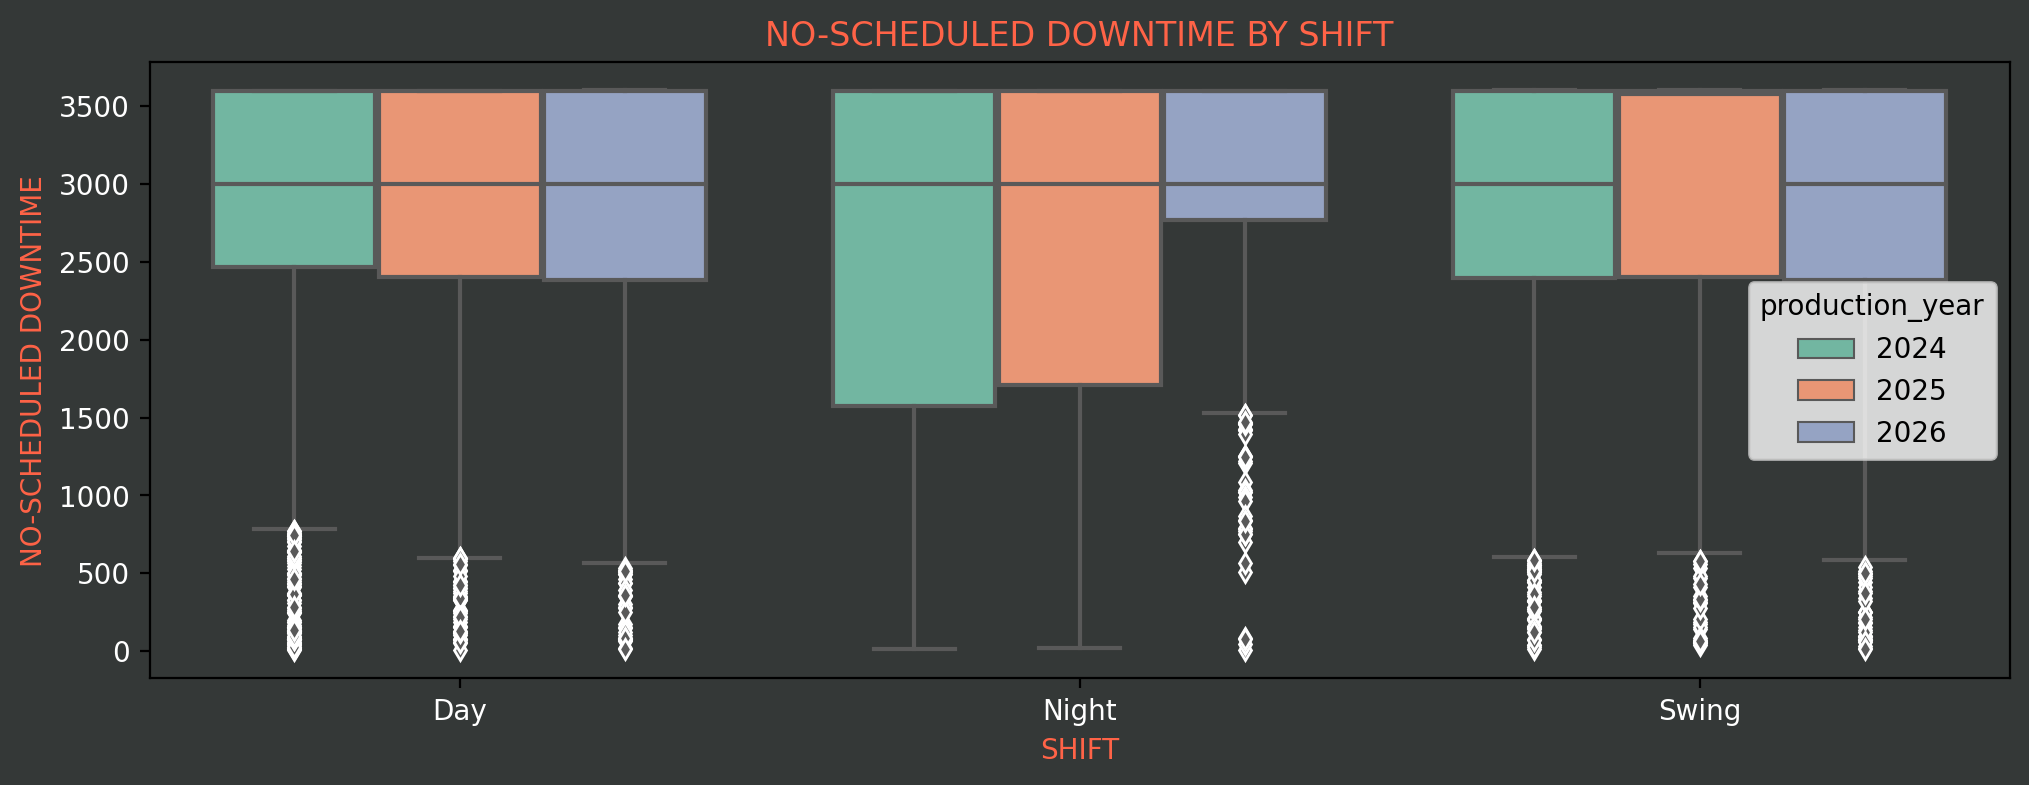

In [118]:
plt.figure(figsize=(12,4), dpi=200)
ax17 = sns.boxplot(nzero_df, x='production_shift', y='total_no_scheduled_downtime', hue='production_year', palette='Set2', flierprops={"markeredgecolor": "white"})

ax17.set_facecolor("#343837")          # Inner color
ax17.figure.set_facecolor("#343837")    # Outer color
ax17.set_xlabel('SHIFT', color='tomato')
ax17.set_ylabel('NO-SCHEDULED DOWNTIME', color='tomato')
ax17.set_title('NO-SCHEDULED DOWNTIME BY SHIFT', color='tomato')
ax17.tick_params(labelcolor='white')
#plt.ylim(300, 500)

c:\Python311\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
c:\Python311\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


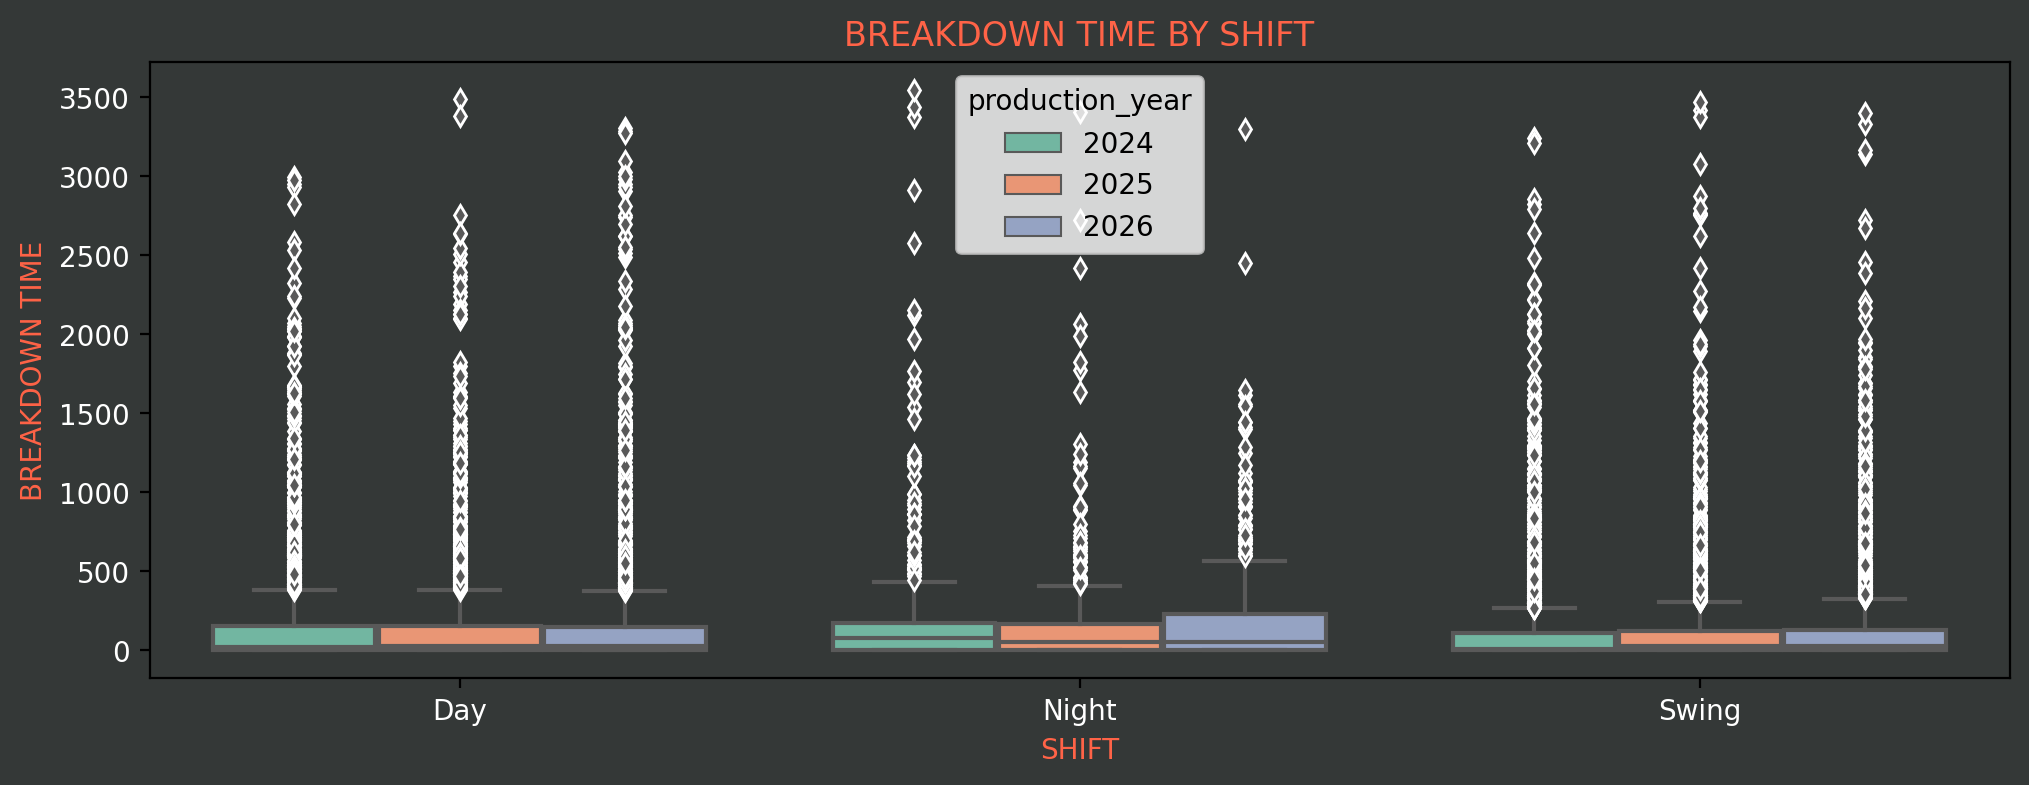

In [119]:
plt.figure(figsize=(12,4), dpi=200)
ax17 = sns.boxplot(nzero_df, x='production_shift', y='machine_breakdown_time', hue='production_year', palette='Set2', flierprops={"markeredgecolor": "white"})

ax17.set_facecolor("#343837")          # Inner color
ax17.figure.set_facecolor("#343837")    # Outer color
ax17.set_xlabel('SHIFT', color='tomato')
ax17.set_ylabel('BREAKDOWN TIME', color='tomato')
ax17.set_title('BREAKDOWN TIME BY SHIFT', color='tomato')
ax17.tick_params(labelcolor='white')
#plt.ylim(300, 500)

c:\Python311\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
c:\Python311\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


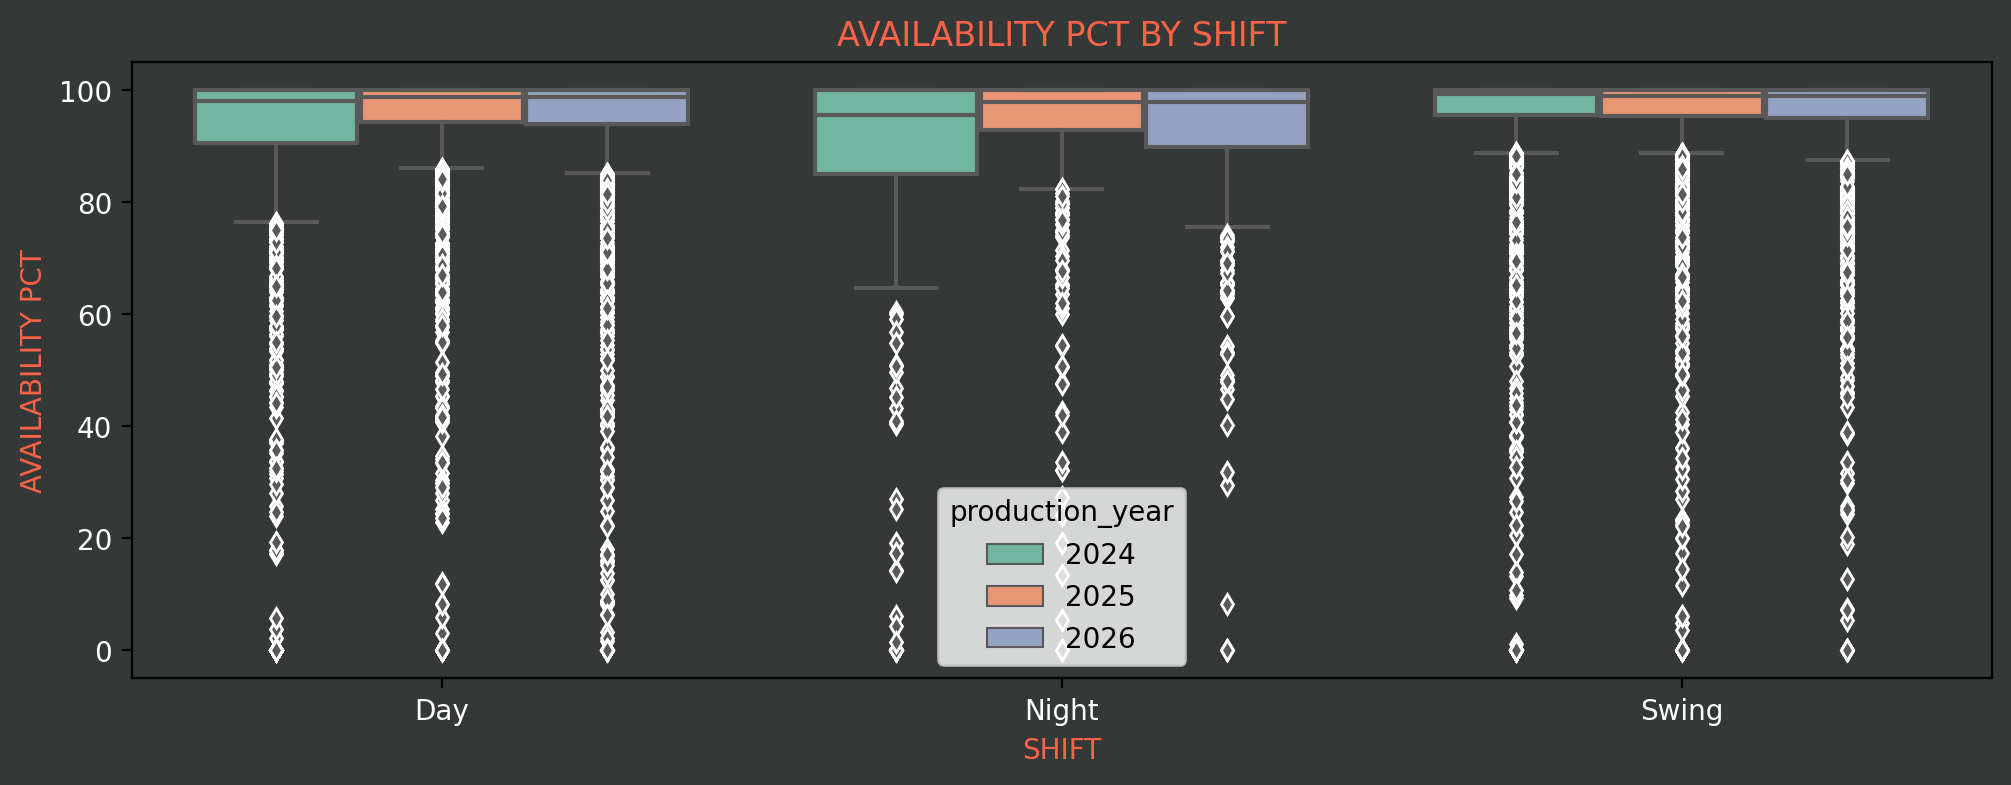

In [120]:
plt.figure(figsize=(12,4), dpi=200)
ax18 = sns.boxplot(nzero_df, x='production_shift', y='machine_availability_percent', hue='production_year', palette='Set2', flierprops={"markeredgecolor": "white"})

ax18.set_facecolor("#343837")          # Inner color
ax18.figure.set_facecolor("#343837")    # Outer color
ax18.set_xlabel('SHIFT', color='tomato')
ax18.set_ylabel('AVAILABILITY PCT', color='tomato')
ax18.set_title('AVAILABILITY PCT BY SHIFT', color='tomato')
ax18.tick_params(labelcolor='white')
#plt.ylim(300, 500)

### Time Analysis

In [143]:
monthly_mac_breakdown_time_df = nzero_df.groupby(pd.Grouper(key='production_datetime', freq='MS'))['machine_breakdown_time'].sum()

c:\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


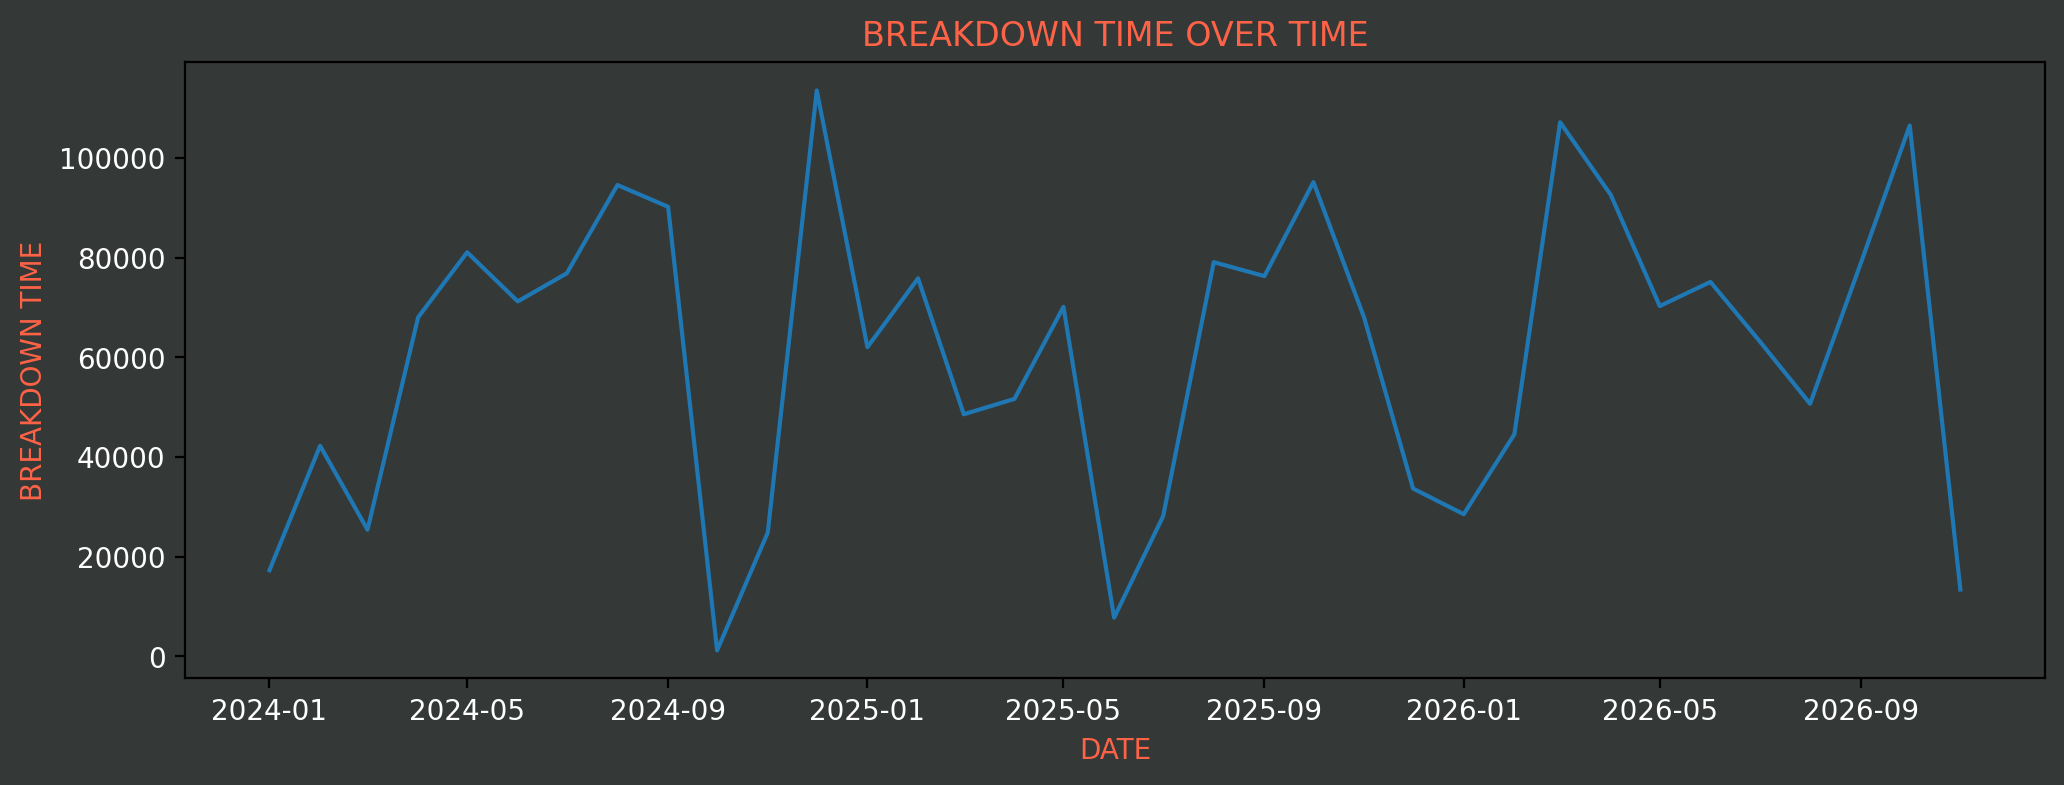

In [145]:
plt.figure(figsize=(12,4), dpi=200)
ax20 = sns.lineplot(monthly_mac_breakdown_time_df, x=monthly_mac_breakdown_time_df.index, y=monthly_mac_breakdown_time_df)

ax20.set_facecolor("#343837")          # Inner color
ax20.figure.set_facecolor("#343837")    # Outer color
ax20.set_xlabel('DATE', color='tomato')
ax20.set_ylabel('BREAKDOWN TIME', color='tomato')
ax20.set_title('BREAKDOWN TIME OVER TIME', color='tomato')
ax20.tick_params(labelcolor='white')